# 实验5B：BERT 情感分类

In [1]:
EXPERIMENT='exp5B'
TITLE='BERT'
from pathlib import Path
import os, sys, random, json, time, copy, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
ROOT=Path.cwd() if (Path.cwd()/'exp5').is_dir() else Path.cwd().parent
BASE=ROOT/'exp5'; DATA=BASE/'data'; CACHE=BASE/'.cache'; RESULT=BASE/'results'/EXPERIMENT
for p in [DATA,CACHE,RESULT]: p.mkdir(parents=True,exist_ok=True)
sys.path.insert(0,str(ROOT/'exp4/.cache/python'))
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(4)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'font.sans-serif':['Microsoft YaHei','SimHei','DejaVu Sans'],'axes.unicode_minus':False,'figure.dpi':110})
SENTENCE='今天终于通过了考试，我真的很开心！'
print(sys.executable,torch.__version__,device)
def savefig(name):
    plt.savefig(RESULT/(name+'.png'),dpi=160,bbox_inches='tight'); plt.show(); plt.close()
def metrics(y,p):
    pr,re,f,_=precision_recall_fscore_support(y,p,labels=[0,1,2],average='macro',zero_division=0)
    return dict(Accuracy=accuracy_score(y,p),Precision_macro=pr,Recall_macro=re,F1_macro=f)
def code_image(code):
    import textwrap
    code='\n'.join(part for line in code.splitlines() for part in (textwrap.wrap(line,width=110,subsequent_indent='    ',replace_whitespace=False) or ['']))
    fig,ax=plt.subplots(figsize=(13,max(3,len(code.splitlines())*.24))); ax.axis('off')
    ax.text(0,1,code,va='top',fontfamily=['Consolas','Microsoft YaHei'],fontsize=9,transform=ax.transAxes); savefig('model_code')


E:\CODE\DeepLearning-exp\.cache\exp5-env\Scripts\python.exe 2.14.1+cu130 cuda


In [2]:
# 缺少本地模型文件时，从指定官方模型仓库下载；以后复用缓存。
import requests
model_files={'google-bert/bert-base-chinese':['config.json','model.safetensors','vocab.txt','tokenizer_config.json','tokenizer.json'],
             'openai-community/openai-gpt':['config.json','model.safetensors','vocab.json','merges.txt','tokenizer_config.json','tokenizer.json']}
needed=list(model_files) if EXPERIMENT=='exp5A' else [list(model_files)[0 if EXPERIMENT=='exp5B' else 1]]
for repo in needed:
    directory=CACHE/repo.split('/')[-1];directory.mkdir(exist_ok=True)
    for filename in model_files[repo]:
        target=directory/filename
        if target.exists():continue
        response=requests.get(f'https://huggingface.co/{repo}/resolve/main/{filename}',stream=True,timeout=180);response.raise_for_status()
        temp=target.with_suffix(target.suffix+'.tmp')
        with temp.open('wb') as f:
            for chunk in response.iter_content(1024*1024):f.write(chunk)
        temp.replace(target)
print('模型文件就绪')


模型文件就绪


## 数据与解释边界
数据来自指定的 [Chinese Multi-Emotion Dialogue Dataset](https://huggingface.co/datasets/Johnson8187/Chinese_Multi-Emotion_Dialogue_Dataset)。繁简转换、去重、排除冲突后分层划分70%/15%/15%；惊奇、关切等映射中性是实验约定，存在语境歧义。测试集只用于最终评价。注意力是权重分布，不能单独当成模型决策的因果解释。

In [3]:
import requests, re
from opencc import OpenCC
from sklearn.model_selection import train_test_split
raw=DATA/'emotion_raw.csv'
if not raw.exists():
    old=ROOT/'exp4/data/emotion_raw.csv'
    if old.exists(): raw.write_bytes(old.read_bytes())
    else:
        r=requests.get('https://huggingface.co/datasets/Johnson8187/Chinese_Multi-Emotion_Dialogue_Dataset/resolve/main/data.csv',timeout=60);r.raise_for_status();raw.write_bytes(r.content)
cc=OpenCC('t2s'); df=pd.read_csv(raw).dropna(subset=['text','emotion'])
mapping={'开心语调':0,'悲伤语调':1,'愤怒语调':1,'厌恶语调':1,'平淡语气':2,'惊奇语调':2,'关切语调':2,'疑问语调':2}
names=['正面','负面','中性']
df['text_clean']=df.text.map(lambda s:re.sub(r'\s+','',cc.convert(s)))
df['label']=df.emotion.map(cc.convert).map(mapping)
assert df.label.notna().all(),df[df.label.isna()].emotion.unique()
conflict=df.groupby('text_clean').label.nunique(); df=df[~df.text_clean.isin(conflict[conflict>1].index)]
df=df[df.text_clean.str.len()>0].drop_duplicates('text_clean').reset_index(drop=True);df.label=df.label.astype(int)
tr,rest=train_test_split(np.arange(len(df)),test_size=.3,stratify=df.label,random_state=SEED)
va,te=train_test_split(rest,test_size=.5,stratify=df.loc[rest,'label'],random_state=SEED)
df['split']='train';df.loc[va,'split']='val';df.loc[te,'split']='test'
df.to_csv(RESULT/'data_split.csv',index=False,encoding='utf-8-sig')
pd.DataFrame([{'original':k,'target':names[v]} for k,v in mapping.items()]).to_csv(RESULT/'label_mapping.csv',index=False,encoding='utf-8-sig')
display(pd.crosstab(df.split,df.label).rename(columns=dict(enumerate(names))))


label,正面,负面,中性
split,,,
test,89,213,322
train,413,992,1502
val,89,212,322


In [4]:
from transformers import BertTokenizer, BertForSequenceClassification
bt=BertTokenizer.from_pretrained(CACHE/'bert-base-chinese')
bert=BertForSequenceClassification.from_pretrained(CACHE/'bert-base-chinese',num_labels=3,attn_implementation='eager').to(device)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: E:\CODE\DeepLearning-exp\exp5\.cache\bert-base-chinese
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your do

In [5]:
def attention_arrays(model,ids,mask=None):
    model.eval()
    with torch.no_grad():
        out=model(input_ids=ids.to(device),attention_mask=None if mask is None else mask.to(device),output_attentions=True)
    a=np.stack([x[0].float().cpu().numpy() for x in out.attentions])
    assert np.isfinite(a).all()
    return a

def attention_plot(a,tokens,title,filename):
    # 每层先对注意力头取均值；多层采用固定的线性深度权重，不是可训练权重，也不等于因果解释。
    per=a.mean(1); w=np.arange(1,len(per)+1,dtype=float);w/=w.sum()
    weighted=np.einsum('l,lij->ij',w,per)
    fig,axes=plt.subplots(1,4,figsize=(19,5),constrained_layout=True)
    for ax,m,label in zip(axes,[per[0],per[5],per[-1],weighted],['第1层','第6层','第12层','多层加权']):
        im=ax.imshow(m,cmap='viridis',vmin=0,vmax=max(float(per.max()),.1))
        ax.set_xticks(range(len(tokens)),tokens,rotation=90,fontsize=6);ax.set_yticks(range(len(tokens)),tokens,fontsize=6)
        ax.set(title=title+' '+label,xlabel='被关注位置 Key',ylabel='查询位置 Query')
    fig.colorbar(im,ax=axes,shrink=.65);savefig(filename)
    np.savez_compressed(RESULT/(filename+'.npz'),attention=a,layer_weights=w,tokens=np.array(tokens))
    return weighted

def compare_attention(before,after,tokens,title):
    b=before.mean(1);a=after.mean(1);w=np.arange(1,13)/78
    mats=[np.einsum('l,lij->ij',w,x) for x in [b,a]]
    fig,axes=plt.subplots(1,3,figsize=(16,5),constrained_layout=True)
    for ax,m,label in zip(axes,[*mats,mats[1]-mats[0]],['训练前','训练后','变化（后－前）']):
        limit=max(abs(mats[1]-mats[0]).max(),1e-8)
        im=ax.imshow(m,cmap='coolwarm' if '变化' in label else 'viridis',vmin=-limit if '变化' in label else 0,vmax=limit if '变化' in label else max(x.max() for x in mats))
        ax.set_xticks(range(len(tokens)),tokens,rotation=90,fontsize=6);ax.set_yticks(range(len(tokens)),tokens,fontsize=6);ax.set_title(title+label);fig.colorbar(im,ax=ax,shrink=.7)
    savefig('attention_before_after')


In [6]:
bi=bt(SENTENCE,return_tensors='pt');tokens=bt.convert_ids_to_tokens(bi.input_ids[0]);before=attention_arrays(bert,bi.input_ids,bi.attention_mask)
np.savez_compressed(RESULT/'attention_before.npz',attention=before,tokens=np.array(tokens))

## 模型微调与验证集选模
5轮，AdamW，学习率3e-5，批量16；最后4层和分类头参与训练。按验证宏F1选择权重。

In [7]:
# 在8GB显存上微调最后4层及分类头；其余层冻结，仍使用完整12层BERT。
for p in bert.parameters():p.requires_grad=False
for layer in bert.bert.encoder.layer[-4:]:
    for p in layer.parameters():p.requires_grad=True
for module in [bert.bert.pooler,bert.classifier]:
    for p in module.parameters():p.requires_grad=True
encoded=bt(df.text_clean.tolist(),padding='max_length',truncation=True,max_length=80,return_tensors='pt')
y=torch.tensor(df.label.to_numpy());loaders={s:DataLoader(TensorDataset(encoded.input_ids[ids],encoded.attention_mask[ids],y[ids]),batch_size=16,shuffle=s=='train') for s,ids in [('train',tr),('val',va),('test',te)]}
optimizer=torch.optim.AdamW([p for p in bert.parameters() if p.requires_grad],lr=3e-5,weight_decay=.01)
def epoch_run(loader,train=False):
    bert.train(train); total=0;count=0;pred=[]
    with torch.set_grad_enabled(train):
        for ids,mask,target in loader:
            ids,mask,target=ids.to(device),mask.to(device),target.to(device)
            with torch.autocast(device_type=device.type,dtype=torch.bfloat16,enabled=device.type=='cuda'):
                o=bert(input_ids=ids,attention_mask=mask,labels=target)
            if train:
                optimizer.zero_grad();o.loss.backward();torch.nn.utils.clip_grad_norm_(bert.parameters(),1);optimizer.step()
            total+=o.loss.item()*len(ids);count+=len(ids);pred.extend(o.logits.argmax(-1).cpu().tolist())
    return total/count,pred
records=[];best=-1;best_epoch=0
for epoch in range(1,6):
    tl,_=epoch_run(loaders['train'],True);vl,vp=epoch_run(loaders['val']);f=metrics(df.loc[va,'label'],vp)['F1_macro'];records.append(dict(epoch=epoch,train_loss=tl,val_loss=vl,val_f1=f))
    if f>best:
        best=f;best_epoch=epoch;torch.save(bert.state_dict(),CACHE/'bert_finetuned.pt')
    print(epoch,records[-1],flush=True)
bert.load_state_dict(torch.load(CACHE/'bert_finetuned.pt',map_location=device,weights_only=True));_,pred=epoch_run(loaders['test'])


1 {'epoch': 1, 'train_loss': 0.378886114911019, 'val_loss': 0.29828013085056077, 'val_f1': 0.8982750995134895}


2 {'epoch': 2, 'train_loss': 0.19897194814076632, 'val_loss': 0.2992111254919972, 'val_f1': 0.9049881488268511}


3 {'epoch': 3, 'train_loss': 0.15295774305362983, 'val_loss': 0.36046041933338296, 'val_f1': 0.8996714456391876}


4 {'epoch': 4, 'train_loss': 0.09375188735739488, 'val_loss': 0.2952245678483579, 'val_f1': 0.9117329798867447}


5 {'epoch': 5, 'train_loss': 0.06398630716319259, 'val_loss': 0.4265747284980111, 'val_f1': 0.9170613805778757}


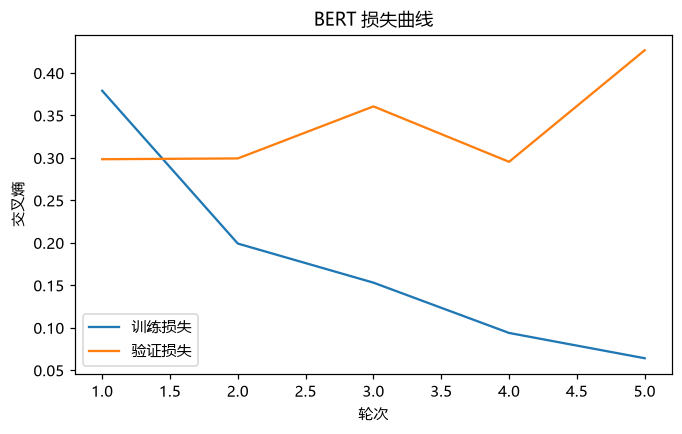

,Accuracy,Precision_macro,Recall_macro,F1_macro,best_epoch
0,0.899038,0.887256,0.891728,0.88899,5


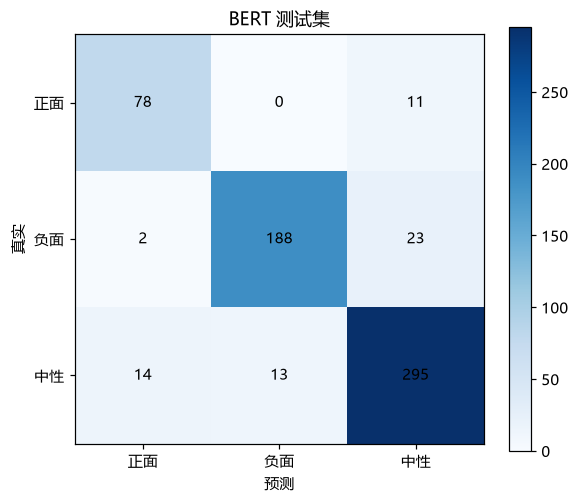

In [8]:
history=pd.DataFrame(records);history.to_csv(RESULT/'training_history.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4));ax.plot(history.epoch,history.train_loss,label='训练损失');ax.plot(history.epoch,history.val_loss,label='验证损失');ax.set(xlabel='轮次',ylabel='交叉熵',title=TITLE+' 损失曲线');ax.legend();savefig('training_curves')
result=metrics(df.loc[te,'label'],pred);result['best_epoch']=best_epoch
pd.DataFrame([result]).to_csv(RESULT/'metrics.csv',index=False);display(pd.DataFrame([result]))
out=df.loc[te,['text_clean','emotion','label']].copy();out['prediction']=pred;out.to_csv(RESULT/'test_predictions.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(classification_report(df.loc[te,'label'],pred,labels=[0,1,2],target_names=names,output_dict=True,zero_division=0)).T.to_csv(RESULT/'class_metrics.csv',encoding='utf-8-sig')
cm=confusion_matrix(df.loc[te,'label'],pred,labels=[0,1,2]);fig,ax=plt.subplots(figsize=(6,5));im=ax.imshow(cm,cmap='Blues');ax.set_xticks(range(3),names);ax.set_yticks(range(3),names);ax.set(xlabel='预测',ylabel='真实',title=TITLE+' 测试集')
for i in range(3):
    for j in range(3):ax.text(j,i,str(cm[i,j]),ha='center',va='center')
fig.colorbar(im,ax=ax);savefig('performance')


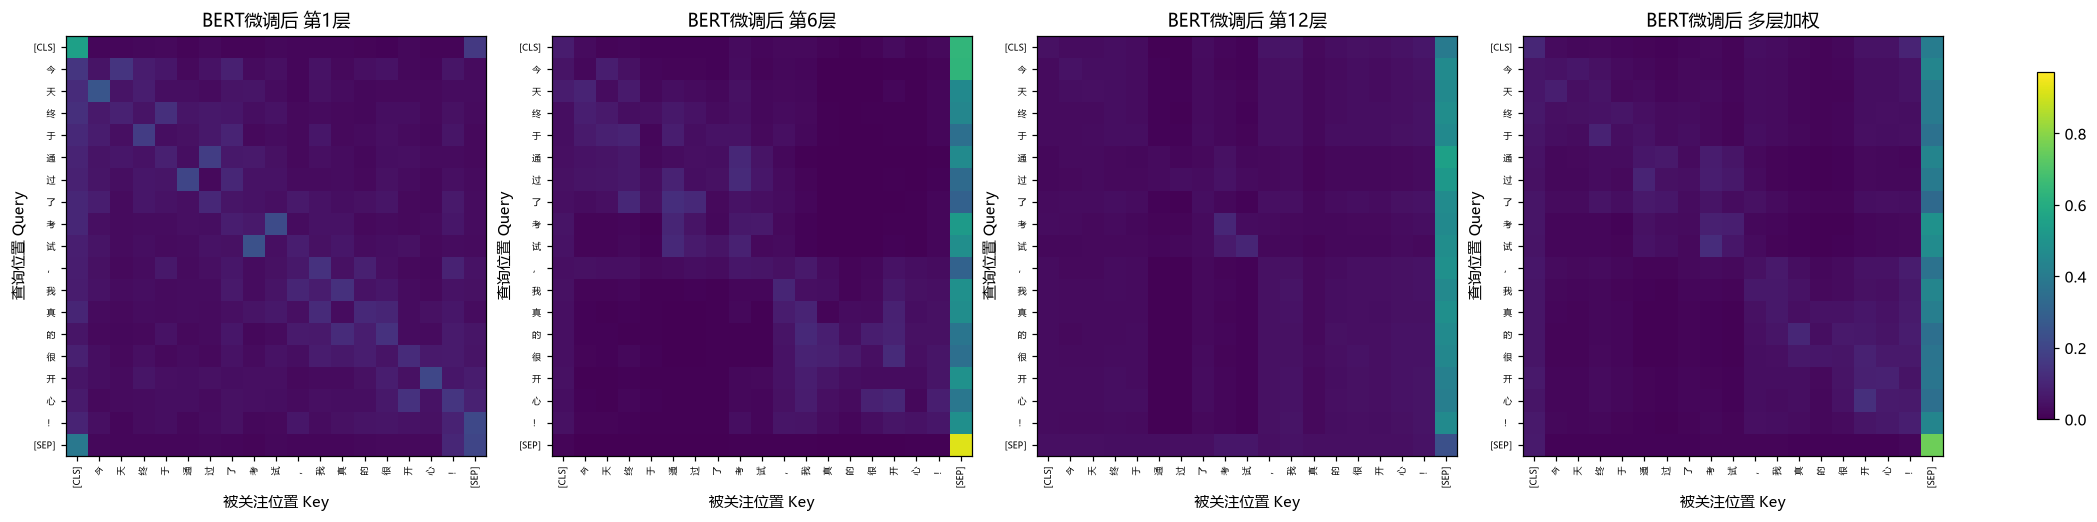

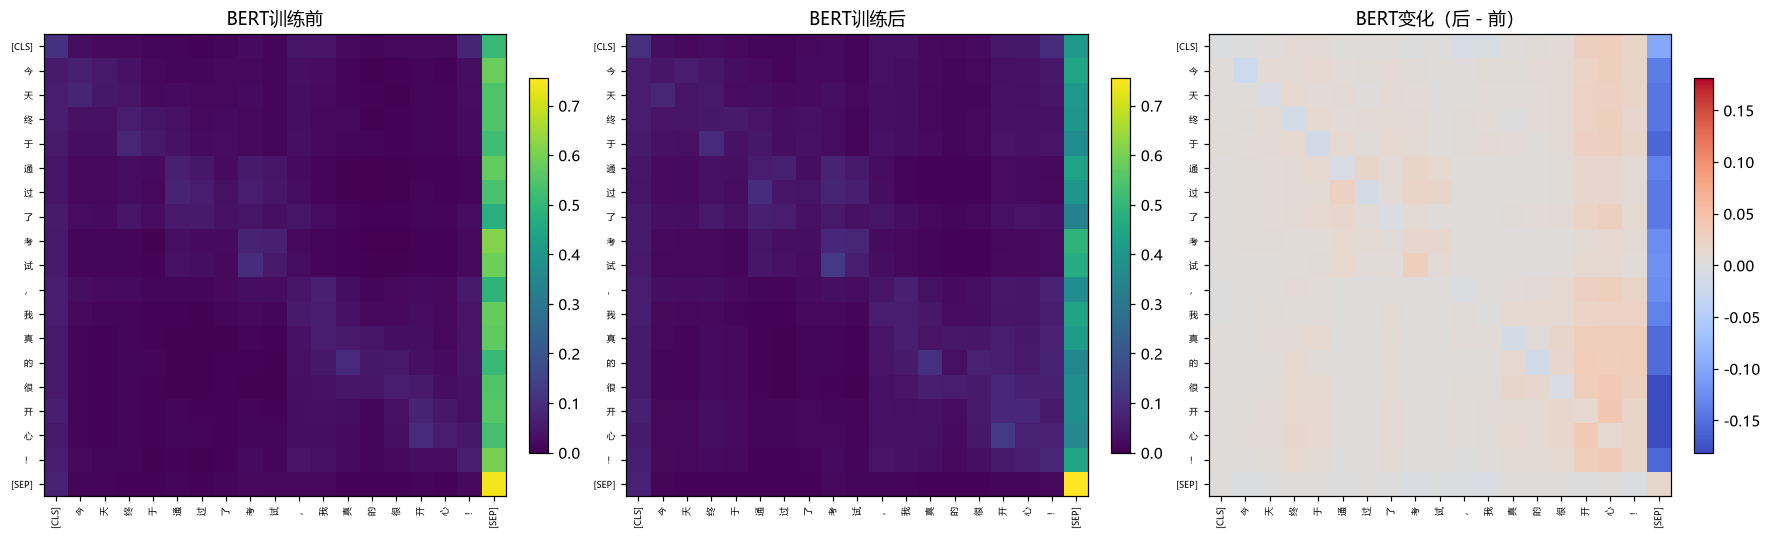

Sentence预测： 正面


In [9]:
after=attention_arrays(bert,bi.input_ids,bi.attention_mask)
attention_plot(after,tokens,'BERT微调后','attention_after')
compare_attention(before,after,tokens,'BERT')
print('Sentence预测：',names[bert(**{k:v.to(device) for k,v in bi.items()}).logits.argmax(-1).item()])

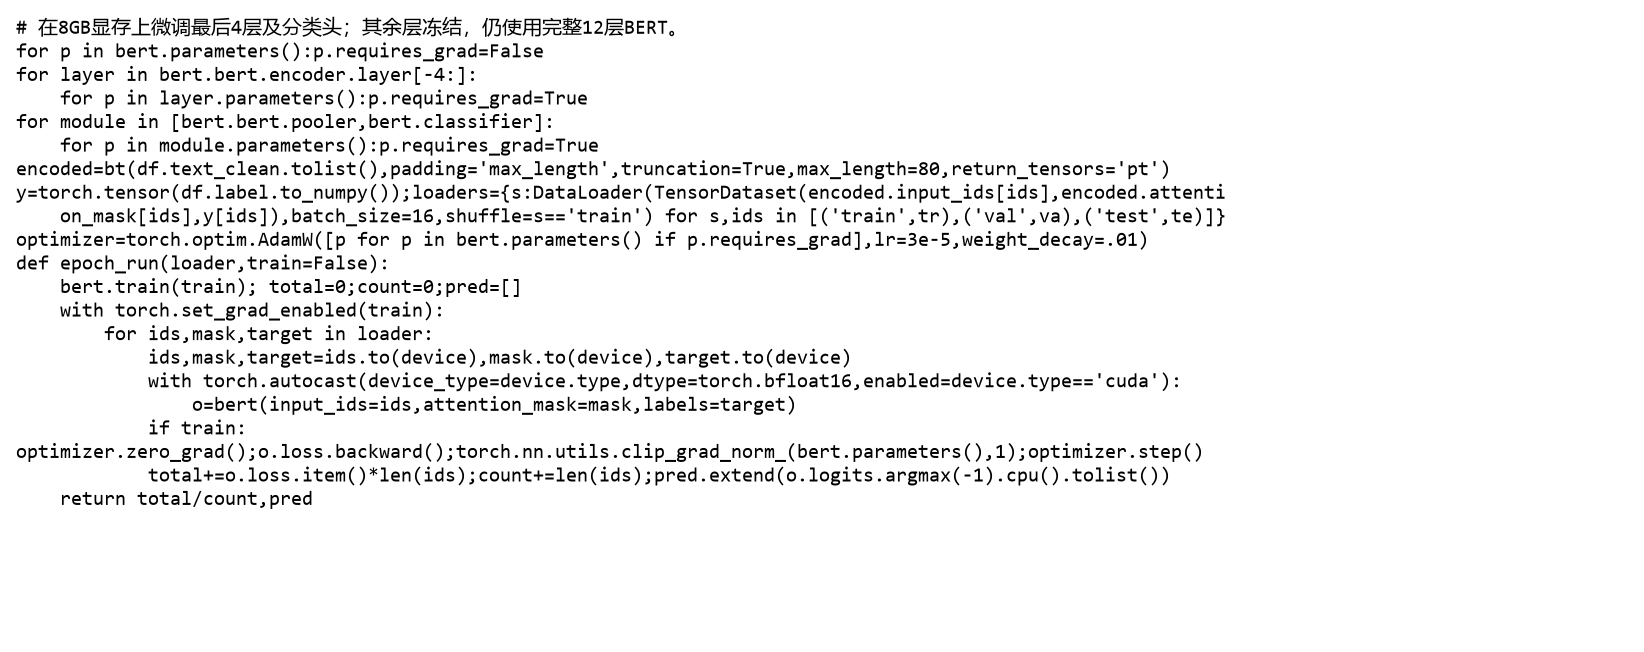

In [10]:
code_image("# 在8GB显存上微调最后4层及分类头；其余层冻结，仍使用完整12层BERT。\nfor p in bert.parameters():p.requires_grad=False\nfor layer in bert.bert.encoder.layer[-4:]:\n    for p in layer.parameters():p.requires_grad=True\nfor module in [bert.bert.pooler,bert.classifier]:\n    for p in module.parameters():p.requires_grad=True\nencoded=bt(df.text_clean.tolist(),padding='max_length',truncation=True,max_length=80,return_tensors='pt')\ny=torch.tensor(df.label.to_numpy());loaders={s:DataLoader(TensorDataset(encoded.input_ids[ids],encoded.attention_mask[ids],y[ids]),batch_size=16,shuffle=s=='train') for s,ids in [('train',tr),('val',va),('test',te)]}\noptimizer=torch.optim.AdamW([p for p in bert.parameters() if p.requires_grad],lr=3e-5,weight_decay=.01)\ndef epoch_run(loader,train=False):\n    bert.train(train); total=0;count=0;pred=[]\n    with torch.set_grad_enabled(train):\n        for ids,mask,target in loader:\n            ids,mask,target=ids.to(device),mask.to(device),target.to(device)\n            with torch.autocast(device_type=device.type,dtype=torch.bfloat16,enabled=device.type=='cuda'):\n                o=bert(input_ids=ids,attention_mask=mask,labels=target)\n            if train:\n                optimizer.zero_grad();o.loss.backward();torch.nn.utils.clip_grad_norm_(bert.parameters(),1);optimizer.step()\n            total+=o.loss.item()*len(ids);count+=len(ids);pred.extend(o.logits.argmax(-1).cpu().tolist())\n    return total/count,pred\n")